# `Library`

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

# `Data Loading & Understanding`

### Data Load

In [2]:
current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)
file_path = os.path.join(parent_dir, "data", "mnist.npz")
df = np.load(file_path)
print(df.files)
x_train = df['x_train']
y_train = df['y_train']
x_test = df['x_test']
y_test = df['y_test']

['x_test', 'x_train', 'y_train', 'y_test']


### Data info

In [3]:
print('x_train shape(Images):', x_train.shape)
print('y_train shape(labels):', y_train.shape)
print('x_test shape(Images):', x_test.shape)
print('y_test shape(labels):', y_test.shape)
print('Image data type:', x_train.dtype)
print('Pixel min:', x_train.min(), '| Pixel max:', x_train.max())
print('Pixel min:', x_test.min(), '| Pixel max:', x_test.max())
print('Unique labels:', np.unique(y_train))

x_train shape(Images): (60000, 28, 28)
y_train shape(labels): (60000,)
x_test shape(Images): (10000, 28, 28)
y_test shape(labels): (10000,)
Image data type: uint8
Pixel min: 0 | Pixel max: 255
Pixel min: 0 | Pixel max: 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]


### NULL Checking

In [4]:
print("x_train (null):", np.isnan(x_train).sum())
print("y_train (null):", np.isnan(y_train).sum())

x_train (null): 0
y_train (null): 0


### Duplicate Checking

In [5]:
flat = x_train.reshape(len(x_train), -1)
dup_count = len(flat) - len(np.unique(flat, axis=0))
print('Duplicate images in train:', dup_count)

Duplicate images in train: 0


### Leakage Checking (Between Train and Test)

In [6]:
train_flat = x_train.reshape(len(x_train), -1)
train_flat.shape

(60000, 784)

In [7]:
test_flat = x_test.reshape(len(x_test), -1)
test_flat.shape

(10000, 784)

In [8]:
train_set = set(map(tuple, train_flat))
leak = 0
for img in test_flat:
    if tuple(img) in train_set:
        leak += 1
print("Data Leakage(Between Train and Test):", leak)

Data Leakage(Between Train and Test): 0


# `Exploratory Data Analysis (EDA)`

### Sample Images

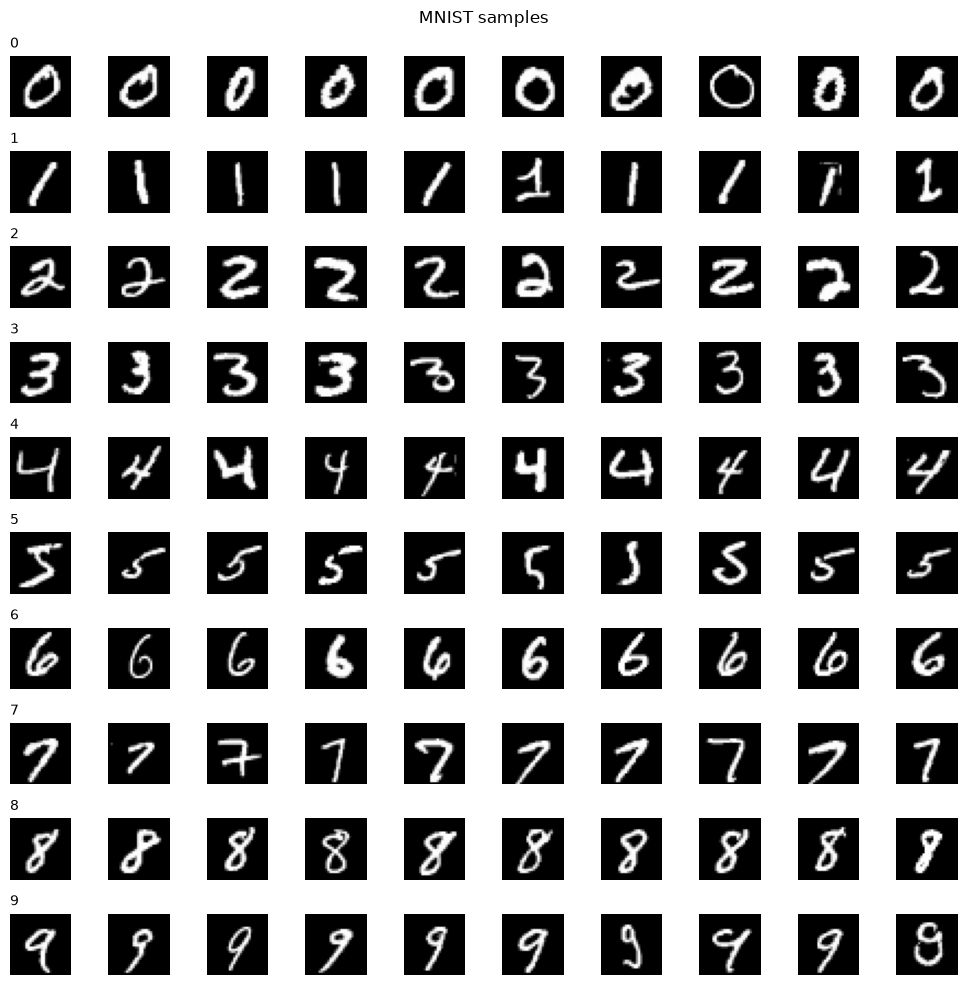

In [9]:
fig, axes = plt.subplots(10, 10, figsize=(10, 10))
for digit in range(10):
    imgs = x_train[y_train == digit][:10]
    for j in range(10):
        axes[digit, j].imshow(imgs[j], cmap='gray')
        axes[digit, j].axis('off')
    axes[digit, 0].set_title(str(digit), fontsize=10, loc='left')
plt.suptitle('MNIST samples')
plt.tight_layout()
plt.show()

### Class Distribution

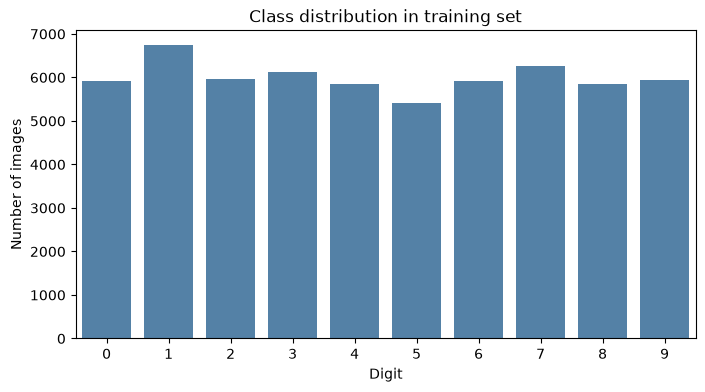

In [10]:
counts = pd.Series(y_train).value_counts().sort_index()
plt.figure(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, color='steelblue')
plt.xlabel('Digit')
plt.ylabel('Number of images')
plt.title('Class distribution in training set')
plt.show()

In [11]:
small = counts.min()
large = counts.max()
print('Smallest class:', small, '| Largest class:', large)

Smallest class: 5421 | Largest class: 6742


# `Data Processing`

### Class Balancing

In [13]:
x_list = []
y_list = []
for digit in range(10):
    imgs = x_train[y_train == digit][:small]
    labels = y_train[y_train == digit][:small]
    x_list.append(imgs)
    y_list.append(labels)
x_bal = np.concatenate(x_list)
y_bal = np.concatenate(y_list)

print('x_bal shape:', x_bal.shape)
print('y_bal shape:', y_bal.shape)

x_bal shape: (54210, 28, 28)
y_bal shape: (54210,)


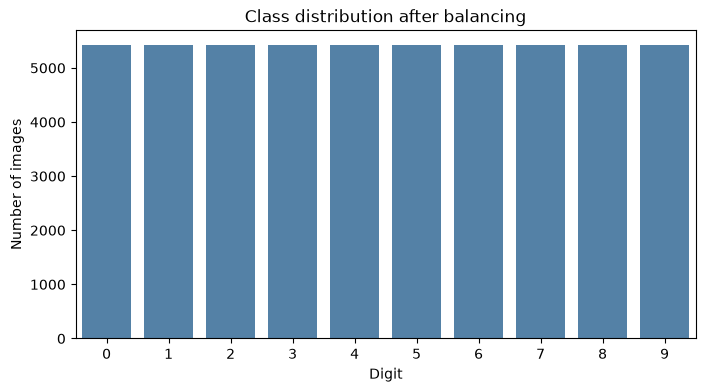

In [20]:
counts_bal = pd.Series(y_bal).value_counts().sort_index()
plt.figure(figsize=(8, 4))
sns.barplot(x=counts_bal.index, y=counts_bal.values, color='steelblue')
plt.xlabel('Digit')
plt.ylabel('Number of images')
plt.title('Class distribution after balancing')
plt.show()

### Normalizing Pixel Values Between(0-1)

In [21]:
x_train = x_train.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0

### Cannel adding

In [22]:
x_bal = x_bal.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)